
## Lineare Regression mit mehreren Features

- Bei fast allen Machine Learning Projekten hängen die Labels von mehreren
  Features ab.
- Eine lineare Regression mit mehreren Features nennt man multivariate lineare
  Regression.
- Die Gleichung wird dann zu y = b + w1*x1 + w2*x2 + ...


- Im folgenden Beispiel wollen wir die Note eines Studenten in der
  Abschlussprüfung vorhersagen.
- Dabei beziehen wir folgende Features mit ein:
  - Note in der Zwischenprüfung
  - Anzahl der Stunden, die für das Lernen aufgewendet wurden
  - Anzahl der versäumten Kurstage

- Wir wollen also eine Funktion finden, die diese Features auf die Note abbildet.


Die Daten sind in der sqlite Datenbank `student_grades.db` gespeichert.

- Laden Sie die Daten aus der Datenbank in "DB Browser for SQLite" und
  analysieren Sie die Struktur der Daten.
- Verwenden Sie anschließend die `sqlite3` Bibliothek, um die Daten aus der
  Datenbank zu laden.
  - Erzeugen Sie eine Liste `student_x` mit den Features als Listen von
    numerischen Werten
  - Erzeugen Sie eine Liste `student_y` mit den Labels als numerischen Werten

In [3]:
import sqlite3

In [6]:
connection = sqlite3.connect("student_grades.db") # create a connection to the database
cursor = connection.cursor()


In [ ]:
cursor.execute(
    "SELECT midterm_grade, study_hours, missed_classes, final_grade FROM grades"
)
rows = cursor.fetchall()
cursor.close()
student_x = [row[:3] for row in rows] 
student_y = [row[3] for row in rows] 

In [9]:
rows[:5]

[(68.6, 24.4, 2, 99.5),
 (81.0, 27.3, 3, 98.7),
 (48.4, 3.6, 2, 40.2),
 (60.0, 18.3, 4, 76.0),
 (68.5, 15.6, 2, 70.6)]


Train-Test-Split der Daten

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [16]:
X_train, X_test, y_train, y_test = train_test_split(student_x, student_y, test_size=0.4, random_state=42)
print(len(X_train), len(X_test))

60 40


In [17]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0.81, 1.78,-5.78]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6.844
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[97.15,68.16,11.01]"


In [18]:
print(f"Coef: {model.coef_}")
print(f"Intercept: {model.intercept_}")
print(f"Score: {model.score(X_test, y_test)}")

Coef: [ 0.81159621  1.78226592 -5.77935407]
Intercept: 6.844139260210483
Score: 0.9465985069051669


In [22]:
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)
print(mean_squared_error(y_test, test_predictions))
print(mean_absolute_error(y_test, test_predictions))    
print(r2_score(y_test, test_predictions)) #mean_squared_error power to 2
print(mean_squared_error(y_train, train_predictions))
print(mean_absolute_error(y_train, train_predictions))
print(r2_score(y_train, train_predictions))

19.159462454654562
3.517436795365943
0.9465985069051669
28.205365801689645
4.1590261786494285
0.9324693267013677


In [24]:
import matplotlib.pyplot as plt

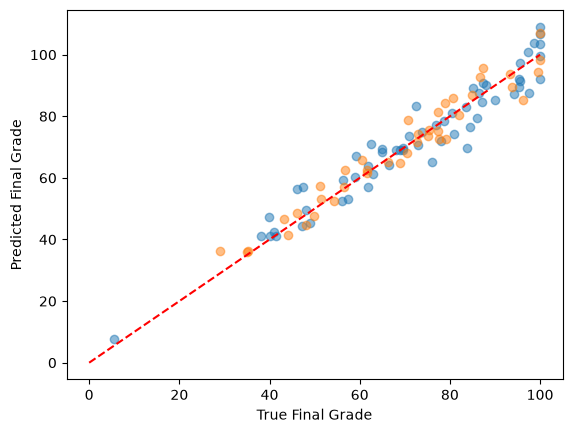

In [25]:
plt.scatter(y_train, train_predictions, alpha=0.5)
plt.scatter(y_test, test_predictions, alpha=0.5)
plt.plot([0, 100], [0, 100], color="red", linestyle="--")
plt.xlabel("True Final Grade")
plt.ylabel("Predicted Final Grade")
plt.show()


Erstellen Sie ein Histogramm der Vorhersagefehler für die Testdaten.


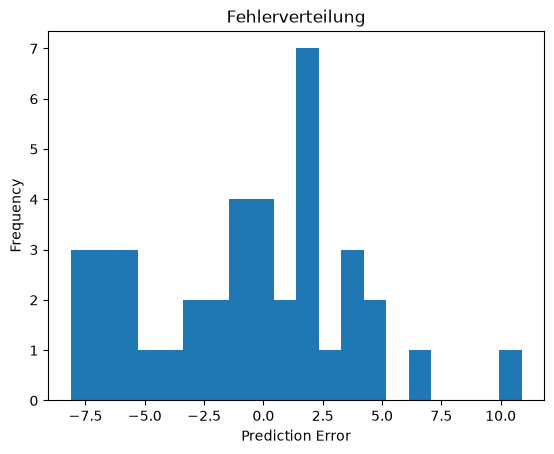

In [27]:
errors = y_test - test_predictions
plt.hist(errors, bins=20)
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Fehlerverteilung")
plt.show()  


### Scatterplots

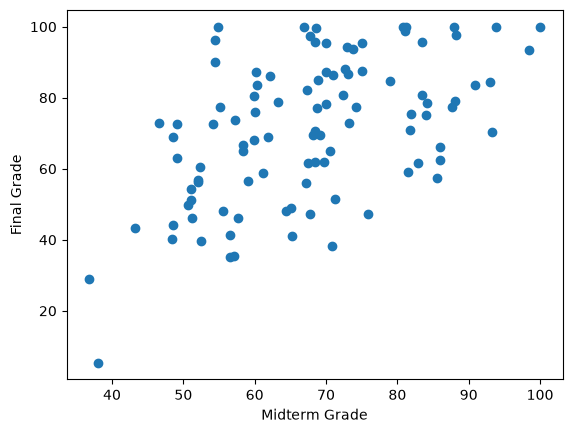

In [28]:
plt.scatter([x[0] for x in student_x], student_y)
plt.xlabel("Midterm Grade")
plt.ylabel("Final Grade")
plt.show()

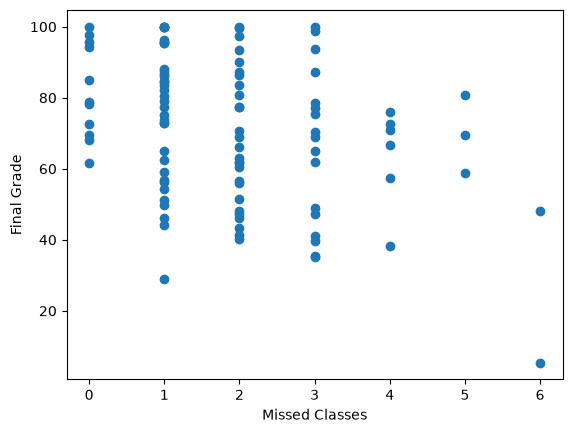

In [29]:
plt.scatter([x[2] for x in student_x], student_y)
plt.xlabel("Missed Classes")
plt.ylabel("Final Grade")
plt.show()

In [32]:
import seaborn as sns
sns.set_theme(style="darkgrid") 

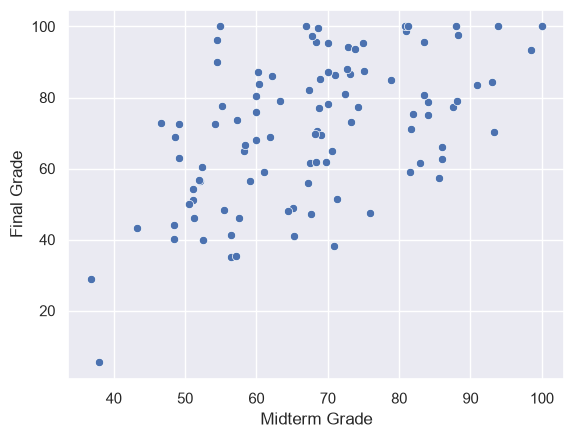

In [33]:
sns.scatterplot(x=[x[0] for x in student_x], y=student_y)
plt.xlabel("Midterm Grade")
plt.ylabel("Final Grade")
plt.show()


### Histogramme

- Ein Histogramm zeigt die Verteilung eines einzelnen Features
- Nützlich, um Ausreißer und die allgemeine Verteilung der Daten zu
  erkennen
- Kann mit Matplotlib erstellt werden

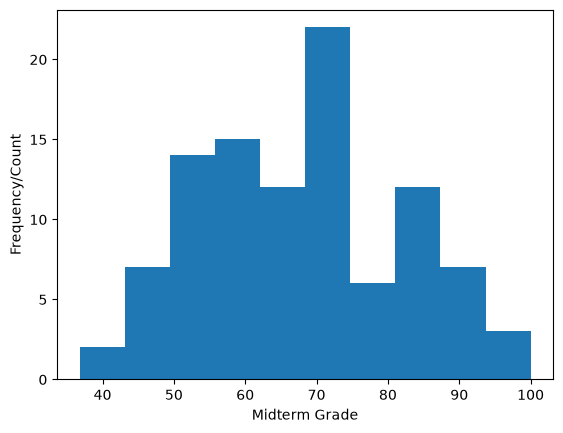

In [30]:
plt.hist([x[0] for x in student_x], bins=10)
plt.xlabel("Midterm Grade")
plt.ylabel("Frequency/Count")
plt.show()

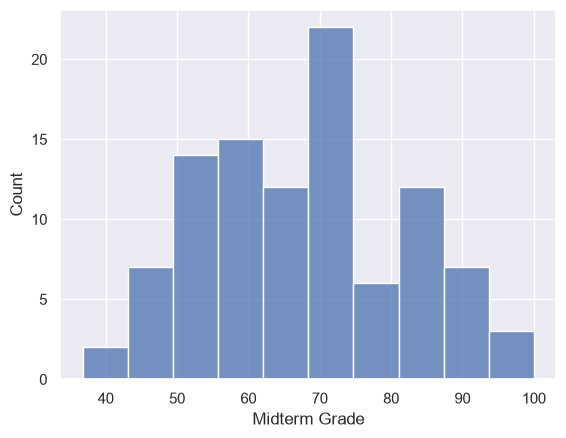

In [34]:
sns.histplot([x[0] for x in student_x], bins=10)
plt.xlabel("Midterm Grade")
plt.show()

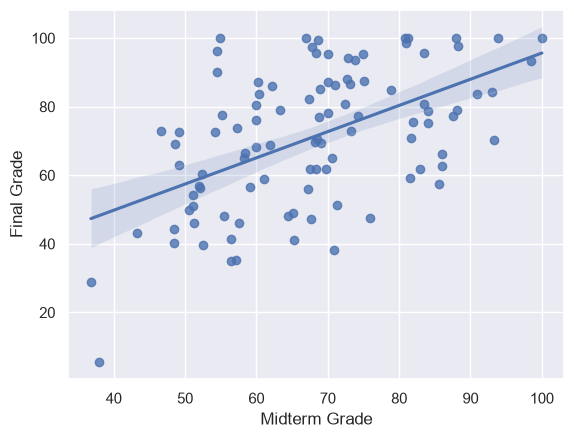

In [35]:
sns.regplot(x=[x[0] for x in student_x], y=student_y)
plt.xlabel("Midterm Grade")
plt.ylabel("Final Grade")
plt.show()

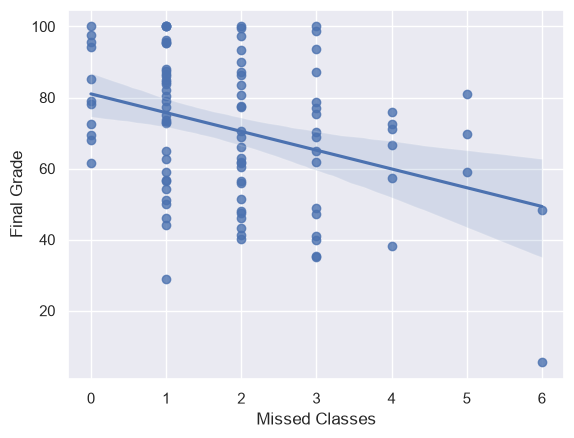

In [36]:
sns.regplot(x=[x[2] for x in student_x], y=student_y)
plt.xlabel("Missed Classes")
plt.ylabel("Final Grade")
plt.show()